# Test 1 – Does our Monte Carlo price match the real market?

In `Simulation_Analysis.ipynb` we checked the simulation against a **formula** (Black–Scholes).
That only proves the code is doing the maths right. This notebook asks a harder question:

> **If we give the simulation real-world inputs, does it come up with the same option prices that real traders are paying?**

### The plan in one picture

```
 real data ──►  S0, r, σ  ──►  Monte Carlo  ──►  "our price"
                                                      │
 real option prices (what traders pay) ───────────────┴──►  compare!
```

### Quick refresher: what is an option?
* A **call** with strike $K$ = the right (not the obligation) to **buy** SPY at price $K$ on the expiry date.
  It pays $\max(S_T - K,\ 0)$, where $S_T$ is SPY's price at expiry.
* A **put** with strike $K$ = the right to **sell** SPY at $K$. It pays $\max(K - S_T,\ 0)$.

Think of a put as **insurance against SPY falling**, and a call as a **lottery ticket on SPY rising**.

### How Monte Carlo prices it (no fancy maths)
1. Simulate lots (here 200,000) of possible SPY prices on the expiry date.
2. Work out what the option would pay in each one.
3. Take the average, and shrink it a little for the time value of money (\$1 later is worth less than \$1 today):

$$\text{price} \approx e^{-rT} \times \text{average payoff}$$

### Sections
1. Load the real data
2. Choose the model inputs ($S_0$, $r$, $\sigma$)
3. Clean up the option prices
4. Price every option with Monte Carlo
5. Compare: how far off are we?
6. *Why* are we off? – the implied-volatility "smile"
7. Takeaways

In [36]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq

# Make the project's src/ folder importable whether we start in the root or in notebooks/.
project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import black_scholes_call, black_scholes_put, price_chain, simulate_terminal_prices
from src.market_data import load_option_chain, load_price_history, load_risk_free_rate, realized_volatility

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.dpi"] = 110

## 1. Load the real data

These files were downloaded earlier by `src/market_data.py` into `data/raw/` (see `data/raw/README.txt`).
To refresh them, run `download_all('SPY')` – ideally **during US market hours**.

| file | what it is |
|---|---|
| `SPY_prices.csv` | SPY's daily price for the last 10 years |
| `risk_free_rate.csv` | the 3-month US T-bill interest rate (our "risk-free rate") |
| `SPY_options_<date>.csv` | a snapshot of real option prices on that day |

In [37]:
TICKER = "SPY"

prices = load_price_history(TICKER)
rates = load_risk_free_rate()
options = load_option_chain(TICKER)          # most recent snapshot

print(f"Price history : {prices.date.min().date()} -> {prices.date.max().date()}  ({len(prices)} days)")
print(f"Option snapshot: {options.snapshot_date.iloc[0].date()}  ({len(options)} contracts)")
print(f"Expiries       : {sorted(options.expiry.dt.date.unique())}")
options.head()

Price history : 2016-11-04 -> 2026-11-03  (2512 days)
Option snapshot: 2026-11-04  (1119 contracts)
Expiries       : [datetime.date(2026, 11, 27), datetime.date(2026, 12, 11), datetime.date(2027, 1, 15), datetime.date(2027, 2, 26)]


,snapshot_date,contract,expiry,days_to_expiry,time_to_maturity,kind,strike,bid,ask,mid,has_quote,last_price,implied_volatility,volume,open_interest,underlying_price,last_trade_date
0,2026-11-04,SPY261127C00510000,2026-11-27,23,0.0630,call,510.0000,0.0000,0.0000,261.4900,False,261.4900,0.0000,1.0000,0,754.3500,2026-10-19 14:18:37+00:00
1,2026-11-04,SPY261127C00515000,2026-11-27,23,0.0630,call,515.0000,0.0000,0.0000,265.4500,False,265.4500,0.0000,NaN,0,754.3500,2026-10-13 14:20:06+00:00
2,2026-11-04,SPY261127C00540000,2026-11-27,23,0.0630,call,540.0000,0.0000,0.0000,241.0200,False,241.0200,0.0000,NaN,0,754.3500,2026-10-09 17:20:41+00:00
3,2026-11-04,SPY261127C00545000,2026-11-27,23,0.0630,call,545.0000,0.0000,0.0000,221.2400,False,221.2400,0.0000,NaN,0,754.3500,2026-10-22 19:58:45+00:00
4,2026-11-04,SPY261127C00560000,2026-11-27,23,0.0630,call,560.0000,0.0000,0.0000,208.3000,False,208.3000,0.0000,NaN,0,754.3500,2026-10-26 16:24:37+00:00


## 2. Choose the model inputs

The simulation needs just three numbers about the market (plus the option's own strike $K$ and time to expiry $T$):

| symbol | meaning | where we get it |
|---|---|---|
| $S_0$ | SPY's price right now | the snapshot's `underlying_price` |
| $r$ | risk-free interest rate | latest T-bill rate (`r_cont`) |
| $\sigma$ | **volatility** – how wildly SPY jumps around, per year | measured from the last 30 / 60 days of SPY prices |

### What is volatility?
Take SPY's daily % moves, measure how spread out they are (the standard deviation), then scale up to a year:

$$\sigma_{\text{year}} = \text{std}(\text{daily returns}) \times \sqrt{252}$$

(252 = trading days in a year. We multiply by $\sqrt{252}$, not 252, because randomness adds up like the
sides of a right-angled triangle, not in a straight line.)

$\sigma = 0.15$ means: "in a typical year SPY moves up or down about 15%".

**$\sigma$ is the most important – and the most uncertain – input.** $S_0$ and $r$ you can just look up. $\sigma$ is about
the *future*, and we're guessing it from the *past*.

S0  (SPY price)        = $754.35
r   (risk-free rate)   = 3.95%
σ   (last 30 days)     = 10.43%
σ   (last 60 days)     = 10.01%
σ   (whole 2 years)    = 18.01%


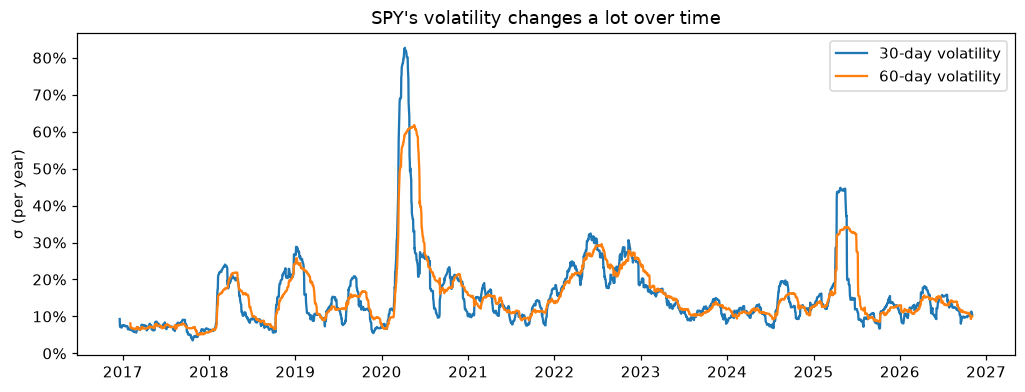

In [38]:
S0 = float(options.underlying_price.iloc[0])
r = float(rates.r_cont.iloc[-1])

vol_30 = realized_volatility(prices.adj_close, window=30)
vol_60 = realized_volatility(prices.adj_close, window=60)
sigma_30, sigma_60 = float(vol_30.iloc[-1]), float(vol_60.iloc[-1])

print(f"S0  (SPY price)        = ${S0:,.2f}")
print(f"r   (risk-free rate)   = {r:.2%}")
print(f"σ   (last 30 days)     = {sigma_30:.2%}")
print(f"σ   (last 60 days)     = {sigma_60:.2%}")
print(f"σ   (whole 2 years)    = {np.log(prices.adj_close).diff().std() * np.sqrt(252):.2%}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(prices.date, vol_30, label="30-day volatility")
ax.plot(prices.date, vol_60, label="60-day volatility")
ax.set(title="SPY's volatility changes a lot over time", ylabel="σ (per year)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(); plt.show()

Notice how $\sigma$ is **not constant** – it spikes when the market panics and calms down afterwards.
Our model assumes a single fixed $\sigma$ forever. Keep that in mind; it comes back in Section 6.

We'll use the **60-day** number as our main guess (less jumpy than 30-day).

In [39]:
SIGMA = sigma_60

## 3. Clean up the option prices

A raw option chain has hundreds of contracts, and many of them are junk for our purpose:

* **Far-away strikes** (e.g. a call at \$1,000 when SPY is \$750) barely trade and their prices are unreliable.
  → keep strikes within **±10%** of $S_0$.
* **Stale prices** – some contracts last traded days ago. → keep only ones that **traded on the latest trading day** and have **volume > 0**.
* **Penny options** – prices under \$0.10 are mostly rounding noise. → drop them.

**The market price we use** is the *mid*: halfway between what buyers offer (bid) and sellers ask (ask).
If the snapshot was taken while the market was closed, there's no live bid/ask, so we fall back on the **last traded price**.

In [40]:
latest_trade_day = options.last_trade_date.str[:10].max()
moneyness = options.strike / S0          # 1.00 = "at the money" (strike = current price)

clean = options[
    (moneyness.between(0.90, 1.10))
    & (options.last_trade_date.str[:10] == latest_trade_day)
    & (options.volume > 0)
    & (options.mid >= 0.10)
].copy()
clean["moneyness"] = clean.strike / S0

print(f"Live bid/ask quotes available for {options.has_quote.mean():.0%} of contracts "
      f"({'market open' if options.has_quote.mean() > 0.5 else 'market was CLOSED - using last traded prices'})")
print(f"Kept {len(clean)} of {len(options)} contracts (all last traded on {latest_trade_day})")
clean.groupby(["expiry", "kind"]).size().unstack()

Live bid/ask quotes available for 5% of contracts (market was CLOSED - using last traded prices)
Kept 389 of 1119 contracts (all last traded on 2026-11-03)


kind,call,put
expiry,,
2026-11-27,80,60
2026-12-11,73,49
2027-01-15,30,28
2027-02-26,38,31


## 4. Price every option with Monte Carlo

For each expiry date:
1. Simulate **200,000** possible SPY prices on that date (`simulate_terminal_prices`).
2. Use that *same* set of simulated prices to price every strike, call and put (`price_chain`).

`price_chain` also gives us:
* a **95% confidence interval** – because Monte Carlo is random, our price has a small margin of error.
  With 200,000 simulations it's usually just a few cents.
* the **Black–Scholes** price – the exact formula answer, as a sanity check that the simulation is working.

In [41]:
N_SIMS = 200_000
rng = np.random.default_rng(42)

results = []
for expiry, group in clean.groupby("expiry"):
    T = float(group.time_to_maturity.iloc[0])
    sim_prices = simulate_terminal_prices(S0, r, SIGMA, T, N_SIMS, rng=rng)
    chain = price_chain(sim_prices, S0, sorted(group.strike.unique()), T, r, SIGMA)
    merged = group.merge(chain, on=["kind", "strike"])
    results.append(merged)

compare = pd.concat(results, ignore_index=True)
compare["error"] = compare.mc_price - compare.mid              # + means our model is too expensive
compare["error_pct"] = compare.error / compare.mid

compare[["expiry", "days_to_expiry", "kind", "strike", "mid", "mc_price", "ci_low", "ci_high", "bs_price", "error", "error_pct"]].head(10)

,expiry,days_to_expiry,kind,strike,mid,mc_price,ci_low,ci_high,bs_price,error,error_pct
0,2026-11-27,23,call,700.0000,57.2300,56.0808,55.9975,56.1641,56.0938,-1.1492,-0.0201
1,2026-11-27,23,call,720.0000,41.6300,36.3042,36.2226,36.3858,36.3160,-5.3258,-0.1279
2,2026-11-27,23,call,730.0000,32.5000,26.8309,26.7530,26.9087,26.8393,-5.6691,-0.1744
3,2026-11-27,23,call,735.0000,27.9000,22.3708,22.2962,22.4455,22.3768,-5.5292,-0.1982
4,2026-11-27,23,call,736.0000,27.1100,21.5108,21.4370,21.5847,21.5161,-5.5992,-0.2065
5,2026-11-27,23,call,737.0000,26.6900,20.6631,20.5901,20.7361,20.6676,-6.0269,-0.2258
6,2026-11-27,23,call,738.0000,26.1500,19.8283,19.7561,19.9004,19.8320,-6.3217,-0.2417
7,2026-11-27,23,call,740.0000,23.8700,18.1991,18.1288,18.2693,18.2021,-5.6709,-0.2376
8,2026-11-27,23,call,742.0000,23.7100,16.6292,16.5609,16.6974,16.6318,-7.0808,-0.2986
9,2026-11-27,23,call,743.0000,21.7600,15.8686,15.8015,15.9357,15.8706,-5.8914,-0.2707


**Sanity check:** `mc_price` and `bs_price` should be almost identical (they're two ways of computing the same model).
If they are, any gap versus `mid` (the market) is about the **model's assumptions**, not a bug in our code.

In [42]:
print(f"Largest |MC - Black-Scholes| gap : ${(compare.mc_price - compare.bs_price).abs().max():.3f}")
print(f"Black-Scholes inside MC's 95% CI : {compare.bs_in_ci.mean():.0%} of options (expect ~95%)")
print(f"Typical MC margin of error (±)   : ${(1.96 * compare.std_error).median():.3f}")

Largest |MC - Black-Scholes| gap : $0.119
Black-Scholes inside MC's 95% CI : 94% of options (expect ~95%)
Typical MC margin of error (±)   : $0.048


## 5. Compare: how far off are we?

Each panel below is one expiry date. The **line** is our Monte Carlo price (with its tiny confidence band);
the **dots** are what the market actually paid.

How to read it:
* Calls get cheaper as the strike goes up (it's harder for SPY to end above a high strike).
* Puts get more expensive as the strike goes up (more likely SPY ends below it).
* Where the dots sit **above** the line, the market thinks the option is worth **more** than our model does.

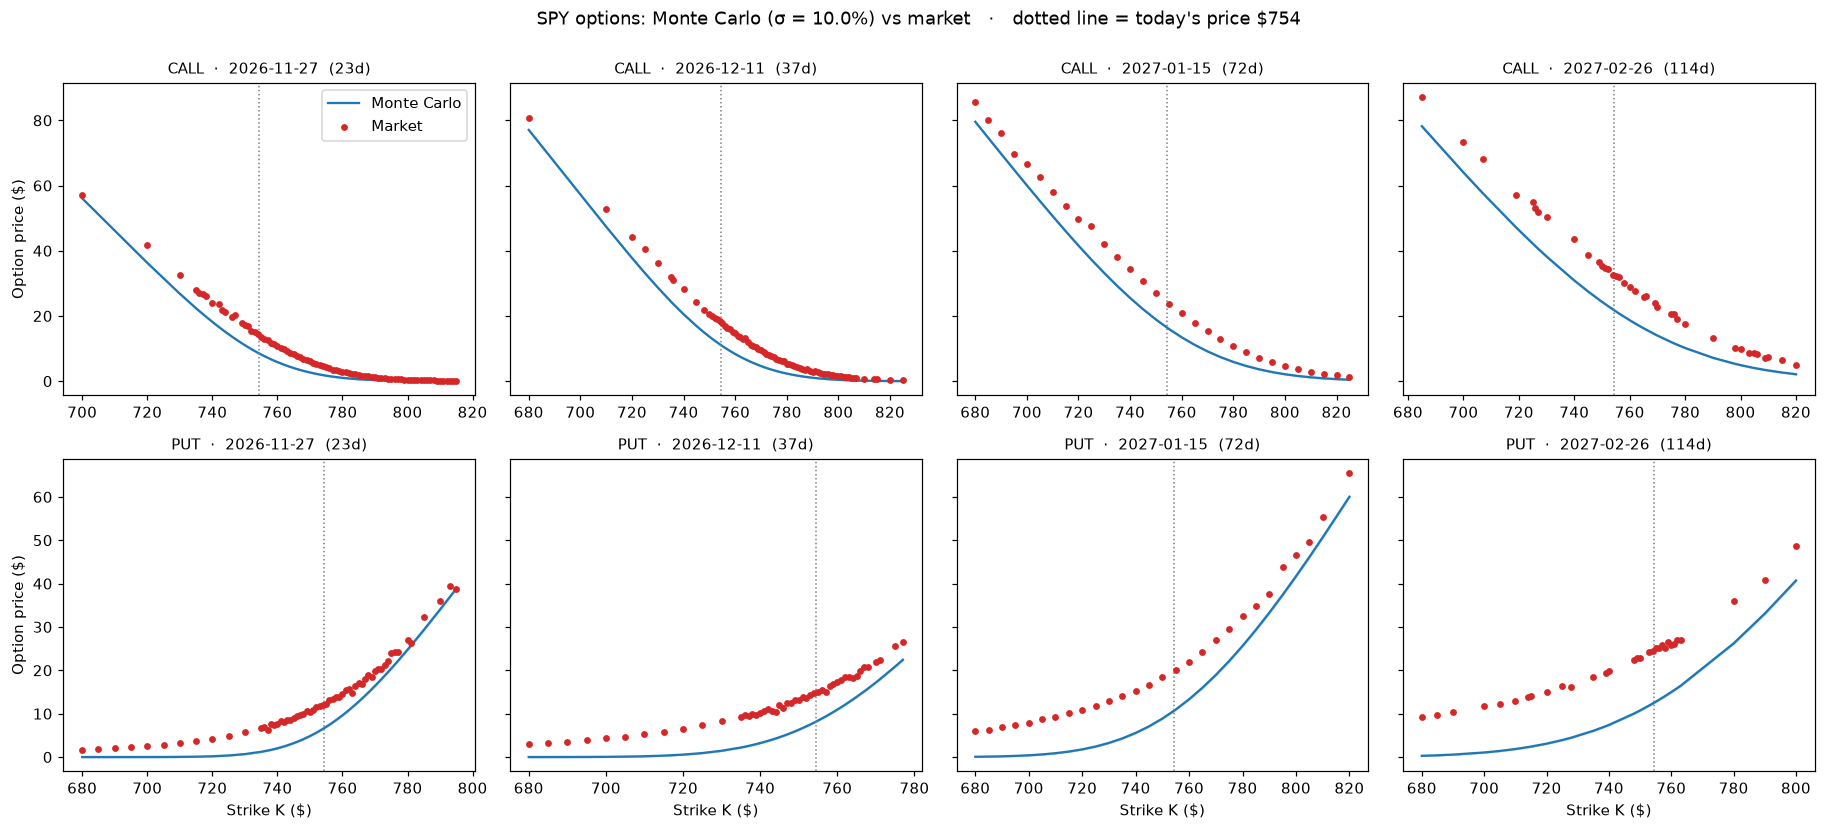

In [43]:
expiries = sorted(compare.expiry.unique())
fig, axes = plt.subplots(2, len(expiries), figsize=(4.2 * len(expiries), 7.5), sharey="row")
axes = np.atleast_2d(axes)

for col, expiry in enumerate(expiries):
    for row, kind in enumerate(["call", "put"]):
        ax = axes[row, col]
        d = compare[(compare.expiry == expiry) & (compare.kind == kind)].sort_values("strike")
        ax.fill_between(d.strike, d.ci_low, d.ci_high, color="tab:blue", alpha=0.25)
        ax.plot(d.strike, d.mc_price, color="tab:blue", label="Monte Carlo")
        ax.scatter(d.strike, d.mid, s=12, color="tab:red", zorder=3, label="Market")
        ax.axvline(S0, color="grey", ls=":", lw=1)
        ax.set_title(f"{kind.upper()}  ·  {pd.Timestamp(expiry).date()}  ({d.days_to_expiry.iloc[0]}d)", fontsize=10)
        if col == 0:
            ax.set_ylabel("Option price ($)")
        if row == 1:
            ax.set_xlabel("Strike K ($)")
axes[0, 0].legend()
fig.suptitle(f"SPY options: Monte Carlo (σ = {SIGMA:.1%}) vs market   ·   dotted line = today's price ${S0:,.0f}", y=1.0)
fig.tight_layout(); plt.show()

### Putting a number on it

Dollar errors are hard to compare (a \$1 error on a \$30 option is small, on a \$2 option it's huge),
so we also look at **% error**:

$$\text{error \%} = \frac{\text{our price} - \text{market price}}{\text{market price}}$$

Negative = our model is **cheaper** than the market.

In [44]:
compare["bucket"] = pd.cut(compare.moneyness, [0.90, 0.95, 0.98, 1.02, 1.05, 1.10],
                           labels=["90-95%", "95-98%", "98-102% (ATM)", "102-105%", "105-110%"])
summary = (compare.groupby(["kind", "bucket"], observed=True)
           .agg(n=("error", "size"), avg_error_dollars=("error", "mean"), avg_error_pct=("error_pct", "mean"))
           .round(3))
summary["avg_error_pct"] = summary.avg_error_pct.map("{:+.0%}".format)
summary

n  avg_error_dollars avg_error_pct
kind bucket                                            
call 90-95%         14            -6.4830          -10%
     95-98%         20            -8.2190          -20%
     98-102% (ATM)  71            -7.0110          -39%
     102-105%       57            -3.2670          -58%
     105-110%       59            -1.3080          -73%
put  90-95%         32            -6.1240          -96%
     95-98%         25            -7.7500          -78%
     98-102% (ATM)  80            -7.1340          -46%
     102-105%       23            -4.2850          -15%
     105-110%        8            -4.4400           -9%

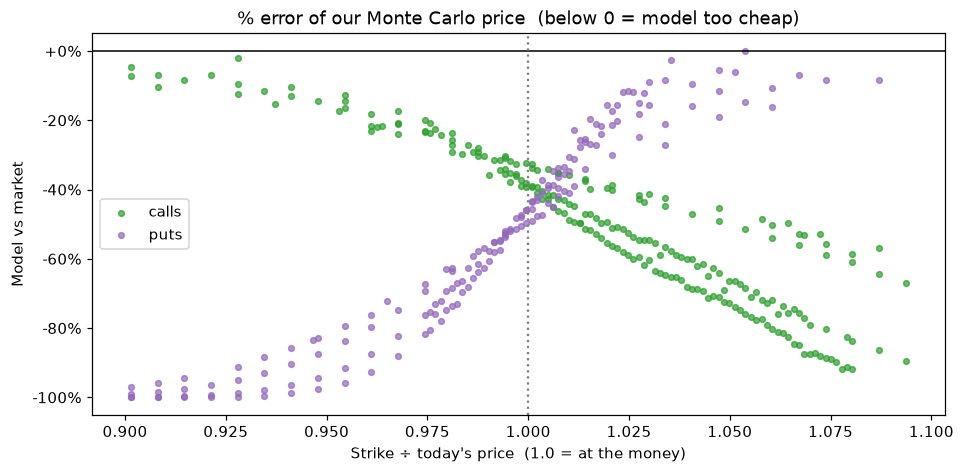

In [45]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for kind, color in [("call", "tab:green"), ("put", "tab:purple")]:
    d = compare[compare.kind == kind]
    ax.scatter(d.moneyness, d.error_pct, s=14, alpha=0.7, color=color, label=f"{kind}s")
ax.axhline(0, color="black", lw=1); ax.axvline(1, color="grey", ls=":")
ax.set(xlabel="Strike ÷ today's price  (1.0 = at the money)", ylabel="Model vs market",
       title="% error of our Monte Carlo price  (below 0 = model too cheap)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:+.0%}"))
ax.legend(); plt.show()

## 6. *Why* are we off? The volatility "smile"

Here's a neat trick. Our model has only one "unknown" input: $\sigma$. So for each market price we can ask:

> **"What $\sigma$ would I have to plug in to get exactly the market's price?"**

That number is called the **implied volatility** – the market's opinion of how jumpy SPY will be.
We find it by trial and error (the computer tries values of $\sigma$ until the Black–Scholes price matches the market price).
We compute it ourselves because Yahoo's own implied-vol column is unreliable when the market is closed.

**If our model were perfect**, every option would give the *same* implied $\sigma$ – a flat line.

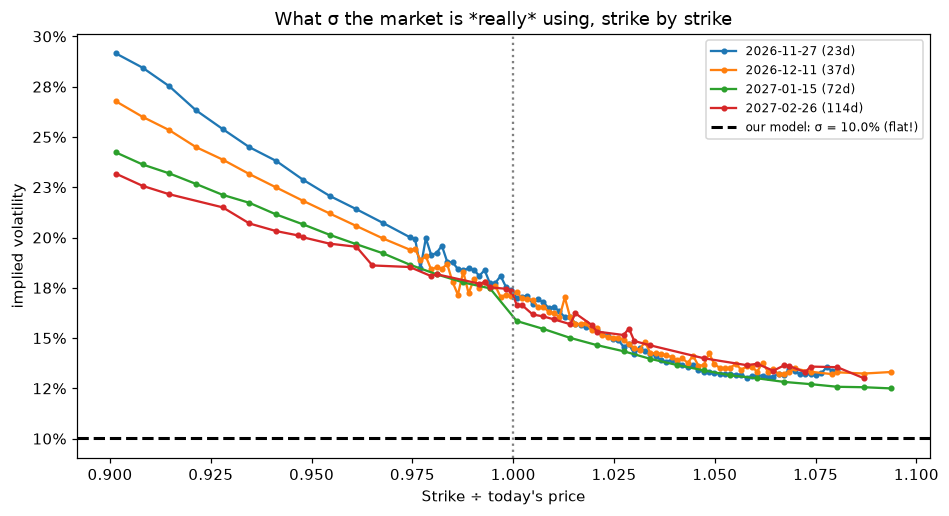

In [46]:
def implied_vol(price, S0, K, T, r, kind):
    # Find the sigma that makes Black-Scholes equal the market price (NaN if impossible).
    f = black_scholes_call if kind == "call" else black_scholes_put
    try:
        return brentq(lambda s: f(S0, K, T, r, s) - price, 1e-4, 3.0)
    except ValueError:
        return np.nan

compare["implied_vol"] = [
    implied_vol(row.mid, S0, row.strike, row.time_to_maturity, r, row.kind) for row in compare.itertuples()
]

# Use out-of-the-money options (puts below S0, calls above S0) - they trade most and are cleanest.
otm = compare[((compare.kind == "put") & (compare.strike <= S0)) | ((compare.kind == "call") & (compare.strike >= S0))]

fig, ax = plt.subplots(figsize=(10, 5))
for expiry in expiries:
    d = otm[otm.expiry == expiry].sort_values("strike")
    ax.plot(d.moneyness, d.implied_vol, marker="o", ms=3, label=f"{pd.Timestamp(expiry).date()} ({d.days_to_expiry.iloc[0]}d)")
ax.axhline(SIGMA, color="black", ls="--", lw=2, label=f"our model: σ = {SIGMA:.1%} (flat!)")
ax.axvline(1, color="grey", ls=":")
ax.set(xlabel="Strike ÷ today's price", ylabel="implied volatility",
       title="What σ the market is *really* using, strike by strike")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.legend(fontsize=8); plt.show()

### How to read this chart

* **The dashed flat line is our model.** It uses the same $\sigma$ for every strike.
* **The coloured curves are the market.** They slope **down to the right** – this is called the **volatility skew** (or "smirk").
* **Left side (low strikes = puts that pay off if SPY crashes):** the market uses a *much higher* $\sigma$.
  Traders know crashes happen faster and more often than a smooth model predicts, so they pay extra for crash insurance.
* **Right side (high strikes):** the market's $\sigma$ is lower – big rallies are less likely than big crashes.

So the gaps in Section 5 aren't random – they follow this pattern exactly. Wherever the curve is above
our dashed line, the market price is above our model price.

In [47]:
atm = otm[(otm.moneyness - 1).abs() < 0.01]
print(f"Our σ (60-day history)              : {SIGMA:.1%}")
print(f"Market's implied σ at the money     : {atm.implied_vol.median():.1%}")
print(f"Market's implied σ at 90% strike    : {otm[otm.moneyness < 0.92].implied_vol.median():.1%}")
print(f"Market's implied σ at 105-110%      : {otm[otm.moneyness > 1.05].implied_vol.median():.1%}")

Our σ (60-day history)              : 10.0%
Market's implied σ at the money     : 17.1%
Market's implied σ at 90% strike    : 24.8%
Market's implied σ at 105-110%      : 13.2%


### Bonus check: is the *Monte Carlo method* fine, and only the σ guess off?

Let's re-price the at-the-money options using the **market's implied σ** instead of our historical one.
If the gap mostly disappears, the simulation is fine – it was just being fed the "wrong" volatility.

In [48]:
rows = []
for expiry in expiries:
    d = compare[(compare.expiry == expiry) & ((compare.moneyness - 1).abs() < 0.01)]
    if d.empty:
        continue
    T = float(d.time_to_maturity.iloc[0])
    iv = float(d.implied_vol.median())
    sims = simulate_terminal_prices(S0, r, iv, T, N_SIMS, rng=rng)
    chain = price_chain(sims, S0, sorted(d.strike.unique()), T, r, iv)
    m = d[["kind", "strike", "mid", "mc_price"]].merge(chain[["kind", "strike", "mc_price"]], on=["kind", "strike"],
                                                    suffixes=("_hist_sigma", "_implied_sigma"))
    m.insert(0, "expiry", pd.Timestamp(expiry).date())
    rows.append(m)
    

atm_fix = pd.concat(rows, ignore_index=True)
print("Average |error| with historical σ:", f"${(atm_fix.mc_price_hist_sigma - atm_fix.mid).abs().mean():.2f}")
print("Average |error| with implied σ   :", f"${(atm_fix.mc_price_implied_sigma - atm_fix.mid).abs().mean():.2f}")
atm_fix

Average |error| with historical σ: $7.61
Average |error| with implied σ   : $0.53


,expiry,kind,strike,mid,mc_price_hist_sigma,mc_price_implied_sigma
0,2026-11-27,call,747.0000,20.2700,13.0000,18.3159
1,2026-11-27,call,749.0000,17.7800,11.6771,17.1381
2,2026-11-27,call,750.0000,17.1400,11.0450,16.5664
3,2026-11-27,call,751.0000,16.7800,10.4329,16.0064
4,2026-11-27,call,752.0000,15.4100,9.8415,15.4584
...,...,...,...,...,...,...
79,2027-02-26,put,757.0000,25.8900,13.6199,25.2601
80,2027-02-26,put,758.0000,25.0900,14.0666,25.7386
81,2027-02-26,put,759.0000,26.4300,14.5226,26.2227
82,2027-02-26,put,760.0000,25.7300,14.9879,26.7123


## 7. Takeaways

*(Written from the 2026-11-04 snapshot. The printed numbers update when you refresh the data, but the pattern usually holds.)*

1. **The code works.** Monte Carlo and the exact Black–Scholes formula agree to within about 10 cents, and the
   confidence intervals behave as they should (~95% coverage).
2. **Our model is too cheap on almost every option – by roughly 40% at the money.** The reason is one number:
   SPY has been unusually *calm* lately (60-day $\sigma \approx 10\%$, versus $\approx 16\%$ over the full 2 years),
   but the market is pricing in about **17%** for the months ahead. Traders don't assume a calm patch will last.
3. **On top of that there's a tilt – the volatility skew.** Low-strike puts (crash insurance) carry an implied $\sigma$
   of ~25%, high-strike calls only ~13%. A single flat $\sigma$ can never fit that, so far-from-the-money puts are
   where our model is most wrong.
4. **Swap in the market's $\sigma$ and the at-the-money error drops from ~\$7.60 to ~\$0.50.** So the simulation
   engine is fine – the real question is *which $\sigma$ to feed it*.

*About the big % errors at the edges of the % chart:* far-from-the-money options cost only a dollar or two,
so even a small dollar gap becomes a huge percentage. Look at both the \$ and the % view.

### "Over/undervalued" – careful with the wording
If our model says \$10 and the market says \$12, it's tempting to say "the option is overvalued".
A fairer statement is: *"the market is pricing in more volatility (X%) than SPY has recently shown (Y%)."*
Sometimes the market is right (it knows about an upcoming event), sometimes history is.

### Other things our model ignores (smaller effects)
* **Dividends** – SPY pays ~1.2% a year. Dividends lower the stock price when paid, which makes calls a bit
  cheaper and puts a bit dearer than our no-dividend model says.
* **Early exercise** – SPY options are *American* (can be exercised any day); our model assumes *European* (expiry only).
* **Stale prices** – if this snapshot was taken while the market was closed, some "market prices" are last trades, not live quotes.

### Next
* **Test 2:** go back in time over the last 2 years and check whether SPY actually landed inside our simulated ranges.